# Series de tiempo, seis predictoras y escenarios hasta 2100

**Estudiante:** Jorge Adalberto Zuñiga Oliva  
**Matrícula:** 82005 · **Grupo:** 512  
**Materia:** Tópicos de Big Data

In [1]:
from pathlib import Path
import sys
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "scripts/curso.py").exists())
sys.path.insert(0, str(RAIZ / "scripts"))
from curso import (leer_owid, metadatos, indicador, solo_paises, guardar_figura,
                   guardar_tabla, U1, U3, SALIDA, FUENTES)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
pd.set_option("display.max_rows", 12)
pd.set_option("display.max_columns", 12)

## 1. Datos, variable objetivo y alcance
El panel contiene entidades y años 2000-2022. Las seis predictoras son población,
nacimientos, defunciones, muertes de menores de cinco años, proporción de gasto sanitario
y PIB por persona. El objetivo es esperanza de vida de periodo, en años.
Se estiman relaciones **contemporáneas**: tener indicadores de un año para estimar el
objetivo de ese mismo año no equivale a pronosticarlo antes de conocer esas entradas.
[Datos de esperanza de vida](https://ourworldindata.org/grapher/life-expectancy).

In [2]:
from sklearn.linear_model import LinearRegression
from sklearn.neural_network import MLPRegressor
from sklearn.dummy import DummyRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.compose import TransformedTargetRegressor
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.base import clone
df = pd.read_csv(U3 / "data/raw/dataset_7variables_2000_2022.csv")
predictoras = ["population", "births", "deaths", "child_deaths_under_5", "percentage_health", "gdp"]
objetivo = "life_expectancy"
assert not df.duplicated(["entity", "year"]).any()
assert np.isfinite(df[predictoras+[objetivo]].to_numpy()).all()
print("Dimensiones:", df.shape, "Entidades:", df.entity.nunique())
display(df.head())

Dimensiones: (4221, 9) Entidades: 186


,entity,year,population,births,deaths,child_deaths_under_5,percentage_health,gdp,life_expectancy
0,Afghanistan,2002,21378123.0,1015202.0,239161.0,123215,9.443391,1774.3087,56.2251
1,Afghanistan,2003,22733053.0,1069727.0,243573.0,123894,8.941258,1815.9282,57.1713
2,Afghanistan,2004,23560656.0,1095372.0,244435.0,122315,9.808474,1776.9182,57.8098
3,Afghanistan,2005,24404575.0,1097038.0,241932.0,118420,9.948289,1908.1147,58.2468
4,Afghanistan,2006,25424100.0,1120880.0,245586.0,116622,10.622766,1929.7239,58.5533


## 2. La serie anual de México
Una serie es una variable de una entidad ordenada en el tiempo. El panel completo contiene
muchas series. `diff` mide cambios anuales; una media móvil de tres años usa solo el año
actual y los dos previos. Ninguna de estas operaciones explica causalmente una variación.

,year,life_expectancy,cambio_anual,media_movil_3
2454,2015,74.432,0.027,74.375
2455,2016,74.376,-0.055,74.404
2456,2017,74.261,-0.115,74.356
2457,2018,74.301,0.040,74.313
2458,2019,74.530,0.229,74.364
2459,2020,70.449,-4.081,73.093
2460,2021,69.750,-0.699,71.576
2461,2022,73.973,4.223,71.391


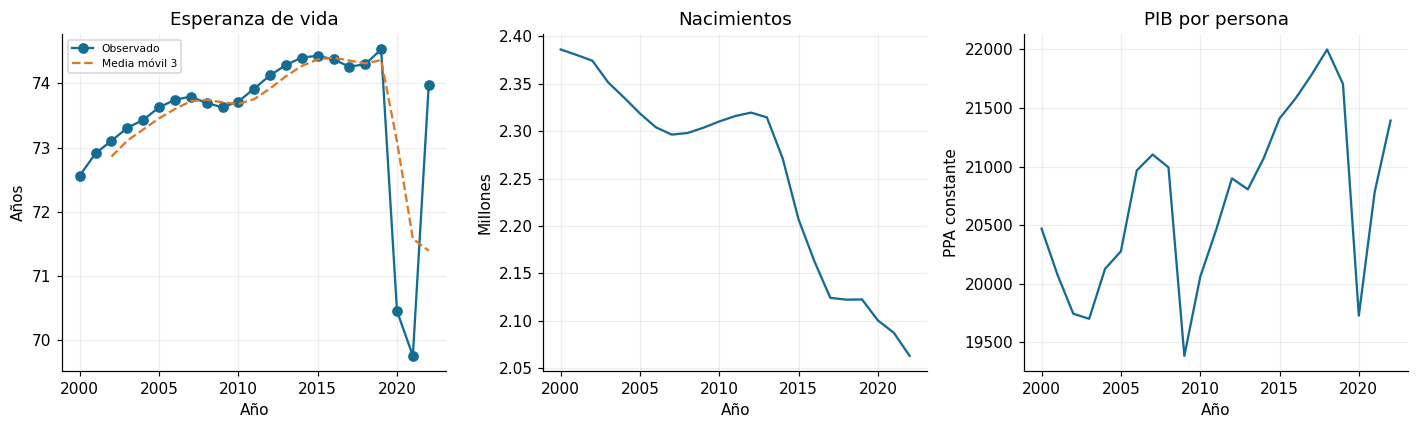

El mayor descenso anual de la esperanza de vida en este recorte aparece en **2020**, con un cambio de **-4.08 años**. La gráfica no identifica su causa.

In [3]:
mx = df.loc[df.entity.eq("Mexico")].sort_values("year").copy()
mx["cambio_anual"] = mx.life_expectancy.diff()
mx["media_movil_3"] = mx.life_expectancy.rolling(3).mean()
display(mx[["year", "life_expectancy", "cambio_anual", "media_movil_3"]].tail(8).round(3))
fig, ejes = plt.subplots(1, 3, figsize=(13, 4))
ejes[0].plot(mx.year, mx.life_expectancy, "o-", label="Observado")
ejes[0].plot(mx.year, mx.media_movil_3, "--", label="Media móvil 3")
ejes[0].set(title="Esperanza de vida", ylabel="Años"); ejes[0].legend(fontsize=7)
ejes[1].plot(mx.year, mx.births/1e6); ejes[1].set(title="Nacimientos", ylabel="Millones")
ejes[2].plot(mx.year, mx.gdp); ejes[2].set(title="PIB por persona", ylabel="PPA constante")
for eje in ejes: eje.set_xlabel("Año")
guardar_figura("U3_4_series_mexico")
peor = mx.dropna(subset=["cambio_anual"]).nsmallest(1, "cambio_anual").iloc[0]
display(Markdown(f"El mayor descenso anual de la esperanza de vida en este recorte aparece en **{int(peor.year)}**, "
                 f"con un cambio de **{peor.cambio_anual:.2f} años**. La gráfica no identifica su causa."))

## 3. Separar antes de escalar
Se fija 2000-2017 para entrenar y 2018-2022 para prueba. Se mantienen países de la
muestra original; la prueba mide generalización a años posteriores de entidades representadas,
no a países nuevos. Los escaladores de X y del objetivo se ajustan solo con entrenamiento.
La arquitectura y la regularización se fijan antes de consultar la prueba.

In [4]:
train = df.loc[df.year.le(2017)].copy()
test = df.loc[df.year.ge(2018)].copy()
assert train.year.max() < test.year.min()
# Solo entidades ya representadas en entrenamiento.
test = test.loc[test.entity.isin(train.entity.unique())].copy()
plantillas = {
    "Media de entrenamiento": DummyRegressor(strategy="mean"),
    "Lineal": make_pipeline(StandardScaler(), LinearRegression()),
    "Red neuronal": TransformedTargetRegressor(
        regressor=make_pipeline(StandardScaler(), MLPRegressor(hidden_layer_sizes=(12, 6),
            solver="lbfgs", alpha=1.0, max_iter=10000, max_fun=100000, tol=1e-4, random_state=82005)),
        transformer=StandardScaler()),
}
evaluados, resultados = {}, []
for nombre, plantilla in plantillas.items():
    modelo = clone(plantilla).fit(train[predictoras], train[objetivo])
    evaluados[nombre] = modelo
    for particion, tabla in [("Entrenamiento", train), ("Prueba 2018-2022", test)]:
        pred = modelo.predict(tabla[predictoras])
        resultados.append({"modelo": nombre, "particion": particion, "filas": len(tabla),
                           "MAE": mean_absolute_error(tabla[objetivo], pred),
                           "RMSE": np.sqrt(mean_squared_error(tabla[objetivo], pred)),
                           "R2": r2_score(tabla[objetivo], pred)})
metricas = pd.DataFrame(resultados)
display(metricas.round(3))
guardar_tabla(metricas, "U3_4_metricas_temporales.csv")

,modelo,particion,filas,MAE,RMSE,R2
0,Media de entrenamiento,Entrenamiento,3293,7.270,8.921,0.000
1,Media de entrenamiento,Prueba 2018-2022,928,6.617,8.069,-0.090
2,Lineal,Entrenamiento,3293,4.782,6.074,0.536
3,Lineal,Prueba 2018-2022,928,4.159,5.441,0.504
4,Red neuronal,Entrenamiento,3293,1.350,1.817,0.959
5,Red neuronal,Prueba 2018-2022,928,1.703,2.207,0.919


CSV guardado: U3_1_modelos_ml/data/processed/U3_4_metricas_temporales.csv (6 filas)


## 4. Qué hacen las transformaciones
`fit` estima parámetros con entrenamiento; `transform` aplica las medias y escalas ya
estimadas; `predict` devuelve una estimación; `inverse_transform` recupera años desde
el objetivo estandarizado. La red tiene seis entradas, capas ocultas de 12 y 6 unidades
y una salida. La regresión usa una combinación lineal; la red puede representar relaciones no lineales.

,entity,year,population,births,deaths,child_deaths_under_5,percentage_health,gdp,life_expectancy
2461,Mexico,2022,128613116.0,2063075.0,838627.0,28309,5.709197,21391.857,73.9731


X: (1, 6) y: (1,)
Entradas transformadas: [[ 0.667  0.52   0.561 -0.08  -0.121  0.012]]
Conexiones de la red: [(6, 12), (12, 6), (6, 1)]
Recuperación del objetivo: [[73.9731]]


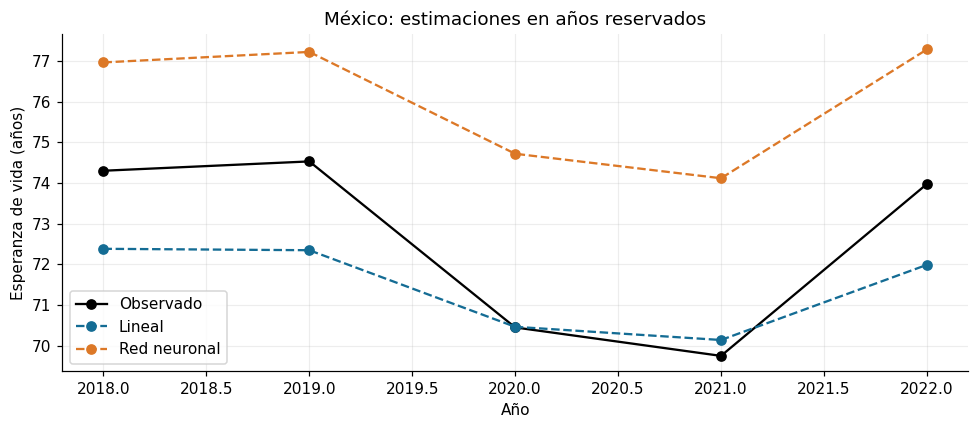

In [5]:
red = evaluados["Red neuronal"]
escalador_x = red.regressor_.named_steps["standardscaler"]
escalador_y = red.transformer_
registro = test.loc[test.entity.eq("Mexico")].tail(1)
display(registro[["entity", "year", *predictoras, objetivo]])
print("X:", registro[predictoras].shape, "y:", registro[objetivo].shape)
print("Entradas transformadas:", escalador_x.transform(registro[predictoras]).round(3))
print("Conexiones de la red:", [peso.shape for peso in red.regressor_.named_steps["mlpregressor"].coefs_])
print("Recuperación del objetivo:", escalador_y.inverse_transform(escalador_y.transform(registro[[objetivo]].to_numpy())))
para_grafica = mx.loc[mx.year.ge(2018)].copy()
plt.plot(para_grafica.year, para_grafica[objetivo], "o-", color="black", label="Observado")
for nombre in ["Lineal", "Red neuronal"]:
    plt.plot(para_grafica.year, evaluados[nombre].predict(para_grafica[predictoras]), "--o", label=nombre)
plt.xlabel("Año"); plt.ylabel("Esperanza de vida (años)")
plt.title("México: estimaciones en años reservados"); plt.legend()
guardar_figura("U3_4_prueba_temporal")

## 5. Escenario con una sola variable
Se usan los modelos evaluados, sin reentrenarlos. Se compara el registro de México en 2022
con otra fila que solo aumenta `gdp` un 10%. Es una consulta al modelo; no estima el efecto
causal de aumentar el PIB. Cambiar únicamente la etiqueta del año no modifica una predicción,
porque el año no es una de las seis entradas.

In [6]:
escenarios = pd.concat([mx.tail(1), mx.tail(1)], ignore_index=True)
escenarios["escenario"] = ["Entradas base de 2022", "Solo PIB +10%"]
escenarios.loc[1, "gdp"] *= 1.10
for nombre in ["Lineal", "Red neuronal"]:
    escenarios[nombre] = evaluados[nombre].predict(escenarios[predictoras])
display(escenarios[["escenario", *predictoras, "Lineal", "Red neuronal"]].round(3))
guardar_tabla(escenarios, "U3_4_sensibilidad_pib.csv")

,escenario,population,births,deaths,child_deaths_under_5,percentage_health,gdp,Lineal,Red neuronal
0,Entradas base de 2022,128613116.0,2063075.0,838627.0,28309,5.709,21391.857,71.988,77.282
1,Solo PIB +10%,128613116.0,2063075.0,838627.0,28309,5.709,23531.043,72.504,77.365


CSV guardado: U3_1_modelos_ml/data/processed/U3_4_sensibilidad_pib.csv (2 filas)


## 6. Reajustar y construir trayectorias hipotéticas
Después de terminar la evaluación se reajustan ambos modelos con 2000-2022 para el
ejercicio de escenarios. Se suponen factores finales respecto de 2022: población 1.05,
nacimientos 0.80, defunciones 1.25, muertes menores de cinco 0.50, salud 1.15 y PIB 1.75.
Se interpola linealmente cada entrada hasta 2100. **Son supuestos didácticos**, no datos
ni proyecciones estimadas para esas seis variables.

In [7]:
finales = {nombre: clone(plantillas[nombre]).fit(df[predictoras], df[objetivo])
           for nombre in ["Lineal", "Red neuronal"]}
base = mx.iloc[-1]
factores = pd.Series([1.05, .80, 1.25, .50, 1.15, 1.75], index=predictoras)
supuestos = pd.DataFrame({"base_2022": base[predictoras].astype(float), "factor_2100": factores})
supuestos["supuesto_2100"] = supuestos.base_2022 * supuestos.factor_2100
display(supuestos.round(3))
futuro = pd.DataFrame({"entity": "Mexico", "year": np.arange(2022, 2101)})
avance = (futuro.year - 2022) / (2100-2022)
for variable in predictoras:
    futuro[variable] = float(base[variable]) * (1 + avance * (factores[variable]-1))
for nombre, modelo in finales.items(): futuro[nombre] = modelo.predict(futuro[predictoras])
fuera = (futuro[predictoras].lt(df[predictoras].min()) | futuro[predictoras].gt(df[predictoras].max()))
futuro["entradas_fuera_rango"] = fuera.sum(axis=1)
assert np.isfinite(futuro[["Lineal", "Red neuronal"]].to_numpy()).all()
guardar_tabla(futuro, "U3_4_escenario_2100.csv")
guardar_tabla(supuestos.reset_index(names="variable"), "U3_4_supuestos_2100.csv")

,base_2022,factor_2100,supuesto_2100
population,1.286131e+08,1.05,1.350438e+08
births,2.063075e+06,0.80,1.650460e+06
deaths,8.386270e+05,1.25,1.048284e+06
child_deaths_under_5,2.830900e+04,0.50,1.415450e+04
percentage_health,5.709000e+00,1.15,6.566000e+00
gdp,2.139186e+04,1.75,3.743575e+04


CSV guardado: U3_1_modelos_ml/data/processed/U3_4_escenario_2100.csv (79 filas)
CSV guardado: U3_1_modelos_ml/data/processed/U3_4_supuestos_2100.csv (6 filas)


## 7. Referencia externa: históricos y escenario medio de OWID/ONU
Se consultan las columnas históricas y proyectadas por separado, con sus metadatos.
Los históricos terminan en 2023 y las proyecciones comienzan en 2024 en esta versión.
La esperanza de vida proyectada por OWID no proporciona población, PIB ni las otras entradas futuras;
no se utiliza para entrenar la red.

Históricos: {'min': 1950, 'max': 2023}
Proyecciones: {'min': 2024, 'max': 2100}


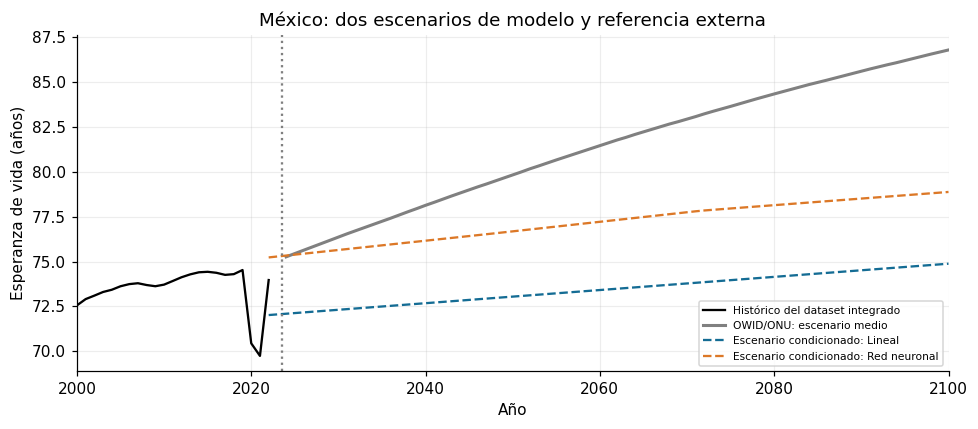

,year,Lineal,Red neuronal,OWID_ONU,entradas_fuera_rango
0,2022,72.02,75.23,NaN,0
8,2030,72.32,75.65,76.37,0
28,2050,73.05,76.68,79.82,0
78,2100,74.88,78.88,86.78,0


In [8]:
slug = "life-expectancy-at-birth-including-the-un-projections"
referencia = leer_owid(slug)
hist = "life_expectancy__sex_all__age_0__variant_estimates"
proy = "life_expectancy__sex_all__age_0__variant_medium__projected"
referencia = referencia.loc[referencia.entity.eq("Mexico")].sort_values("year")
print("Históricos:", referencia.loc[referencia[hist].notna(), "year"].agg(["min", "max"]).to_dict())
print("Proyecciones:", referencia.loc[referencia[proy].notna(), "year"].agg(["min", "max"]).to_dict())
plt.plot(mx.year, mx.life_expectancy, color="black", label="Histórico del dataset integrado")
plt.plot(referencia.year, referencia[proy], color="gray", lw=2, label="OWID/ONU: escenario medio")
for nombre in ["Lineal", "Red neuronal"]:
    plt.plot(futuro.year, futuro[nombre], "--", label=f"Escenario condicionado: {nombre}")
plt.xlim(2000, 2100); plt.axvline(2023.5, color="gray", ls=":")
plt.xlabel("Año"); plt.ylabel("Esperanza de vida (años)")
plt.title("México: dos escenarios de modelo y referencia externa"); plt.legend(fontsize=7)
guardar_figura("U3_4_escenarios_2100")
tabla = futuro.merge(referencia[["year", proy]].rename(columns={proy: "OWID_ONU"}), on="year", how="left")
display(tabla.loc[tabla.year.isin([2022, 2030, 2050, 2100]), ["year", "Lineal", "Red neuronal", "OWID_ONU", "entradas_fuera_rango"]].round(2))

## 8. Respuestas de cierre
1. **Serie de tiempo:** esperanza de vida anual de México; el panel reúne series de muchas entidades.
2. **Cambios observados:** la tabla y las gráficas localizan variaciones en esperanza de vida,
   nacimientos y PIB; su coincidencia no demuestra causalidad.
3. **Seis entradas y una salida:** X tiene seis columnas numéricas; y es un vector de años de vida.
4. **Escalado:** los parámetros se aprenden con entrenamiento y se reutilizan sin reajustarlos en prueba.
5. **Comparación:** la tabla de MAE/RMSE permite comparar años reservados; no permite declarar un ganador hasta 2100.
6. **Cambio de PIB:** la tabla de sensibilidad registra entrada y salida sin alterar las otras cinco variables.
7. **Datos futuros faltantes:** una curva de esperanza de vida no contiene las seis predictoras requeridas.
8. **Por qué difieren las curvas:** los modelos tienen familias distintas y reciben supuestos; no deben
   forzarse a coincidir con OWID ni anclarse artificialmente al valor observado.
Un valor dentro del rango individual de cada columna tampoco garantiza que su combinación
sea conocida. Las trayectorias de 2100 deben interpretarse como escenarios condicionados.
[MLP y escalado](https://scikit-learn.org/stable/modules/neural_networks_supervised.html) ·
[Prevención de fuga de información](https://scikit-learn.org/stable/common_pitfalls.html).